# Experiment-Guided Config C vs IP

Experiment-guided configuration selected from Experiment 8. This notebook does not tune or compare alternatives. Development CV is reported for continuity, and the final holdout cell evaluates the reserved last 20% once.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import hilbert, welch
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, roc_auc_score
from sklearn.preprocessing import RobustScaler, StandardScaler
from mne.filter import filter_data
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")


def find_source_dir():
    candidates = []
    if IN_COLAB:
        candidates.append(Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi"))
    candidates.extend([NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent / "src"])
    for candidate in candidates:
        if (candidate / "br_analysis" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate br_analysis. Add the project src folder to sys.path.")


SRC_DIR = find_source_dir()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    TARGET_BANDS_CLUSTERS,
)
from br_analysis.experiments import chronological_group_labels, stratified_group_splits

mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

paths = detect_project_paths("experiment_guided_config_c_ip", in_colab=IN_COLAB)
task = get_task_config("c_vs_ip", paths.analysis_root)
TASK_TAG = "experiment_guided_config_c_ip"
RANDOM_SEED = 42
HOLDOUT_FRAC = 0.20


SELECTED_CONFIG = {
    "task_label": "C vs IP",
    "model_family": "Riemann",
    "normalization": "trial_zscore",
    "spatial": "All",
    "band": "Broadband",
    "time_scope": "full",
    "riemann_cov": "oas",
}


print("Experiment-guided config:")
print(pd.Series(SELECTED_CONFIG).to_string())
print("Analysis dir:", paths.analysis_dir)

Experiment-guided config:
task_label            C vs IP
model_family          Riemann
normalization    trial_zscore
spatial                   All
band                Broadband
time_scope               full
riemann_cov               oas
Analysis dir: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\experiment_guided_config_c_ip


In [2]:
spec = RawEpochSpec(
    picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0, analysis_window=(0.0, 1.5), peak_align_all_channels=True
)
dataset = load_raw_epoch_dataset(paths, task, spec, verbose=False)
X = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
ch_names = list(dataset.channel_names)
times = np.asarray(dataset.times)
sfreq = 128.0
subject_ids = pd.unique(subjects).tolist()

print(f"X: {X.shape} | classes: {np.bincount(y)} | subjects: {len(subject_ids)}")

X: (5870, 60, 192) | classes: [2935 2935] | subjects: 24


In [3]:
ROI_CHANS = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
CLUSTER_CHANS = list(TARGET_BANDS_CLUSTERS["theta"]) + list(TARGET_BANDS_CLUSTERS["alpha"])


def subject_development_holdout_indices(n_samples, holdout_frac=HOLDOUT_FRAC):
    cutoff = int(np.floor((1.0 - holdout_frac) * n_samples))
    cutoff = max(1, min(cutoff, n_samples - 1))
    return np.arange(cutoff), np.arange(cutoff, n_samples)


def select_and_filter(X_sub, *, spatial, band, time_scope):
    if spatial == "ROI":
        picks = [ch for ch in ROI_CHANS if ch in ch_names]
    elif spatial == "Cluster":
        picks = [ch for ch in CLUSTER_CHANS if ch in ch_names]
    elif spatial == "All":
        picks = ch_names
    else:
        raise ValueError(f"Unknown spatial scope: {spatial}")
    pick_idx = [ch_names.index(ch) for ch in picks]

    if band == "Theta":
        lf, hf = 5.0, 7.0
    elif band == "Alpha":
        lf, hf = 8.0, 12.0
    elif band == "Theta + Alpha":
        lf, hf = 5.0, 12.0
    elif band == "Broadband":
        lf, hf = 1.0, 40.0
    else:
        raise ValueError(f"Unknown band: {band}")

    if time_scope == "conflict":
        t_mask = (times >= 0.375) & (times <= 1.242)
    elif time_scope == "0.5-1s":
        t_mask = (times >= 0.5) & (times <= 1.0)
    elif time_scope == "full":
        t_mask = (times >= 0.0) & (times <= 1.5)
    else:
        raise ValueError(f"Unknown time scope: {time_scope}")

    X_sel = X_sub[:, pick_idx][..., t_mask]
    X_filt = filter_data(X_sel.astype(np.float64), sfreq=sfreq, l_freq=lf, h_freq=hf, method="iir", verbose=False)
    return X_filt.astype(np.float32), lf, hf


def trial_zscore(X_train, X_test):
    def _std(arr):
        mean = arr.mean(axis=-1, keepdims=True)
        std = np.maximum(arr.std(axis=-1, keepdims=True), 1e-6)
        return ((arr - mean) / std).astype(np.float32)

    return _std(X_train), _std(X_test)


def robust_scale_features(X_train, X_test):
    scaler = RobustScaler()
    return scaler.fit_transform(X_train), scaler.transform(X_test)


def regularize_spd_matrices(mats, eps=1e-5):
    mats = np.asarray(mats, dtype=np.float64)
    mats = np.nan_to_num(mats, nan=0.0, posinf=0.0, neginf=0.0)
    mats = 0.5 * (mats + np.swapaxes(mats, -1, -2))
    out = np.empty_like(mats)
    eye = np.eye(mats.shape[-1], dtype=np.float64)
    for i, mat in enumerate(mats):
        eigvals, eigvecs = np.linalg.eigh(mat + eps * eye)
        eigvals = np.maximum(eigvals, eps)
        repaired = (eigvecs * eigvals) @ eigvecs.T
        out[i] = 0.5 * (repaired + repaired.T)
    return out


def fit_predict_best(X_train, y_train, X_test, *, lf, hf):
    if SELECTED_CONFIG["model_family"] == "Riemann":
        if SELECTED_CONFIG["normalization"] == "trial_zscore":
            X_train, X_test = trial_zscore(X_train, X_test)
        elif SELECTED_CONFIG["normalization"] == "robust_scaler":
            n_ch, n_t = X_train.shape[1], X_train.shape[2]
            train_2d, test_2d = robust_scale_features(
                X_train.reshape(len(X_train), -1), X_test.reshape(len(X_test), -1)
            )
            X_train = train_2d.reshape(len(X_train), n_ch, n_t)
            X_test = test_2d.reshape(len(X_test), n_ch, n_t)
        cov = Covariances(estimator=SELECTED_CONFIG.get("riemann_cov", "oas"))
        X_train_cov = regularize_spd_matrices(cov.fit_transform(X_train))
        X_test_cov = regularize_spd_matrices(cov.transform(X_test))
        ts = TangentSpace(metric="riemann")
        X_train_feat = ts.fit_transform(X_train_cov, y_train)
        X_test_feat = ts.transform(X_test_cov)
        clf = LDA(solver="lsqr", shrinkage="auto")
    else:
        if SELECTED_CONFIG.get("ml_features") == "psd_welch":
            f, psd_train = welch(X_train, fs=sfreq, axis=-1)
            _, psd_test = welch(X_test, fs=sfreq, axis=-1)
            f_mask = (f >= lf) & (f <= hf)
            X_train_feat = psd_train[..., f_mask].mean(axis=-1)
            X_test_feat = psd_test[..., f_mask].mean(axis=-1)
        else:
            X_train_feat = np.abs(hilbert(X_train, axis=-1)).mean(axis=-1)
            X_test_feat = np.abs(hilbert(X_test, axis=-1)).mean(axis=-1)
        if SELECTED_CONFIG["normalization"] == "robust_scaler":
            X_train_feat, X_test_feat = robust_scale_features(X_train_feat, X_test_feat)
        elif SELECTED_CONFIG["normalization"] == "zscore":
            scaler = StandardScaler()
            X_train_feat = scaler.fit_transform(X_train_feat)
            X_test_feat = scaler.transform(X_test_feat)
        clf = LogisticRegression(
            C=SELECTED_CONFIG.get("ml_lr_c", 1.0),
            penalty="l2",
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_SEED,
        )
    clf.fit(X_train_feat, y_train)
    prob = clf.predict_proba(X_test_feat)[:, 1] if hasattr(clf, "predict_proba") else clf.decision_function(X_test_feat)
    pred = clf.predict(X_test_feat)
    return pred, prob


def metric_row(subject, split_name, y_true, y_pred, y_score):
    row = {
        "Subject": subject,
        "Split": split_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "N Test": len(y_true),
    }
    try:
        row["ROC AUC"] = roc_auc_score(y_true, y_score)
    except ValueError:
        row["ROC AUC"] = np.nan
    return row

## Development CV

Uses only the development portion. The final 20% per subject remains excluded.

In [4]:
dev_rows = []
oof_true = []
oof_pred = []
oof_score = []
oof_by_subject = {}

for sub in subject_ids:
    mask = subjects == sub
    X_sub = X[mask]
    y_sub = y[mask]
    X_cfg, lf, hf = select_and_filter(
        X_sub,
        spatial=SELECTED_CONFIG["spatial"],
        band=SELECTED_CONFIG["band"],
        time_scope=SELECTED_CONFIG["time_scope"],
    )
    splits = stratified_group_splits(
        y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5, holdout_frac=HOLDOUT_FRAC
    )
    sub_true = []
    sub_pred = []
    sub_score = []
    for fold, (train_idx, val_idx) in enumerate(splits, start=1):
        pred, score = fit_predict_best(X_cfg[train_idx], y_sub[train_idx], X_cfg[val_idx], lf=lf, hf=hf)
        dev_rows.append(metric_row(sub, f"dev_fold_{fold}", y_sub[val_idx], pred, score))
        oof_true.extend(y_sub[val_idx])
        oof_pred.extend(pred)
        oof_score.extend(score)
        sub_true.extend(y_sub[val_idx])
        sub_pred.extend(pred)
        sub_score.extend(score)
    if sub_true:
        oof_by_subject[sub] = {
            "y_true": np.asarray(sub_true),
            "y_pred": np.asarray(sub_pred),
            "prob": np.asarray(sub_score),
        }

df_dev = pd.DataFrame(dev_rows)
dev_path = paths.tables_dir / f"{TASK_TAG}_development_cv.csv"
df_dev.to_csv(dev_path, index=False)

oof_payload = {}
for sub, pred_data in oof_by_subject.items():
    oof_payload[f"{sub}_y_true"] = pred_data["y_true"]
    oof_payload[f"{sub}_y_pred"] = pred_data["y_pred"]
    oof_payload[f"{sub}_prob"] = pred_data["prob"]
oof_payload["_cache_version"] = np.array("stratified_group_kfold_holdout_v1")
oof_payload["_cv_strategy"] = np.array("stratified_group_kfold_development_only")
oof_payload["_holdout_frac"] = np.array(HOLDOUT_FRAC)
oof_path = paths.cache_dir / "oof_predictions_c_vs_ip_experiment_guided.npz"
np.savez_compressed(oof_path, **oof_payload)

print("Development CV saved to:", dev_path)
print("OOF predictions saved to:", oof_path)
print(df_dev.groupby("Subject")[["Accuracy", "Balanced Accuracy", "ROC AUC"]].mean().describe().to_string())
print("\nOOF development classification report:")
print(classification_report(oof_true, oof_pred, target_names=[task.class_0, task.class_1], zero_division=0.0))

Development CV saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\experiment_guided_config_c_ip\tables\experiment_guided_config_c_ip_development_cv.csv
OOF predictions saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\experiment_guided_config_c_ip\cache\oof_predictions_c_vs_ip_experiment_guided.npz
        Accuracy  Balanced Accuracy    ROC AUC
count  24.000000          24.000000  24.000000
mean    0.560425           0.567057   0.589747
std     0.083483           0.066976   0.077373
min     0.392308           0.464261   0.477329
25%     0.503385           0.515410   0.522708
50%     0.565622           0.568995   0.585891
75%     0.622471           0.605013   0.647830
max     0.750000           0.674501   0.748108

OOF development classification report:
                  precision    recall  f1-score   support

       Congruent       0.56      0.55      0.56      2327
Incongruent_Pure       0.57  

## Final Holdout

This is the honest final test for this pre-specified experiment-guided config. Do not use this result to change the config afterwards.

Final holdout saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\experiment_guided_config_c_ip\tables\experiment_guided_config_c_ip_final_holdout_ONCE.csv
        Accuracy  Balanced Accuracy    ROC AUC
count  24.000000          24.000000  24.000000
mean    0.578100           0.569313   0.612438
std     0.093549           0.080735   0.097949
min     0.428571           0.426768   0.414141
25%     0.517098           0.513702   0.559015
50%     0.575292           0.580821   0.597616
75%     0.612204           0.620874   0.661654
max     0.791667           0.743421   0.837302

FINAL HOLDOUT classification report:
                  precision    recall  f1-score   support

       Congruent       0.58      0.64      0.61       608
Incongruent_Pure       0.57      0.52      0.55       576

        accuracy                           0.58      1184
       macro avg       0.58      0.58      0.58      1184
    weighted avg       0.58      0.58      0.58

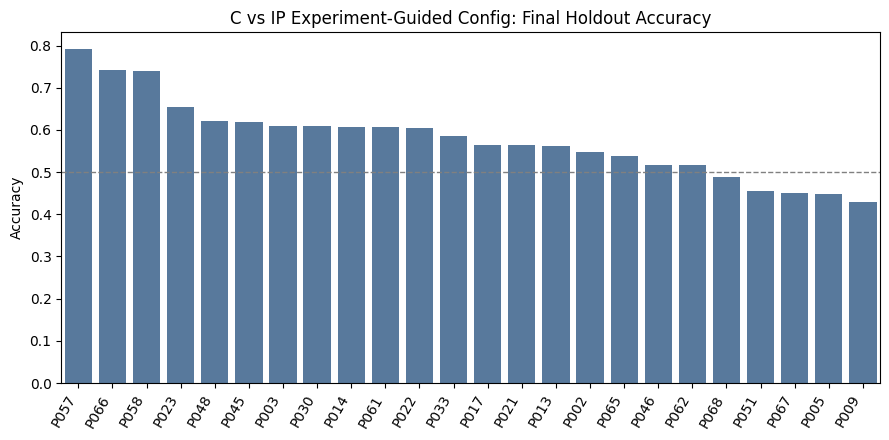

Figure saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\experiment_guided_config_c_ip\figures\experiment_guided_config_c_ip_final_holdout_accuracy.png


In [5]:
final_rows = []
final_true = []
final_pred = []
final_score = []
for sub in subject_ids:
    mask = subjects == sub
    X_sub = X[mask]
    y_sub = y[mask]
    dev_idx, holdout_idx = subject_development_holdout_indices(len(y_sub), HOLDOUT_FRAC)
    if len(np.unique(y_sub[dev_idx])) < 2 or len(np.unique(y_sub[holdout_idx])) < 2:
        print(f"Skipping {sub}: final holdout lacks both classes")
        continue
    X_cfg, lf, hf = select_and_filter(
        X_sub,
        spatial=SELECTED_CONFIG["spatial"],
        band=SELECTED_CONFIG["band"],
        time_scope=SELECTED_CONFIG["time_scope"],
    )
    pred, score = fit_predict_best(X_cfg[dev_idx], y_sub[dev_idx], X_cfg[holdout_idx], lf=lf, hf=hf)
    final_rows.append(metric_row(sub, "final_holdout", y_sub[holdout_idx], pred, score))
    final_true.extend(y_sub[holdout_idx])
    final_pred.extend(pred)
    final_score.extend(score)

df_final = pd.DataFrame(final_rows)
final_path = paths.tables_dir / f"{TASK_TAG}_final_holdout_ONCE.csv"
df_final.to_csv(final_path, index=False)
print("Final holdout saved to:", final_path)
print(df_final[["Accuracy", "Balanced Accuracy", "ROC AUC"]].describe().to_string())
print("\nFINAL HOLDOUT classification report:")
print(classification_report(final_true, final_pred, target_names=[task.class_0, task.class_1], zero_division=0.0))

plt.figure(figsize=(9, 4.5))
order = df_final.sort_values("Accuracy", ascending=False)["Subject"]
sns.barplot(data=df_final, x="Subject", y="Accuracy", order=order, color="#4C78A8")
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
plt.title(f"{SELECTED_CONFIG['task_label']} Experiment-Guided Config: Final Holdout Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
fig_path = paths.figures_dir / f"{TASK_TAG}_final_holdout_accuracy.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print("Figure saved to:", fig_path)